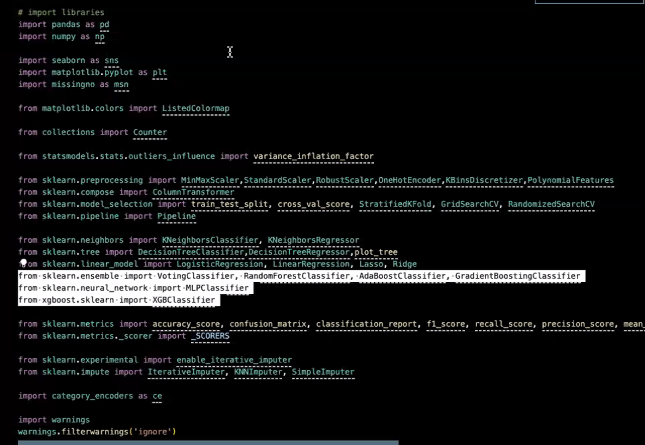

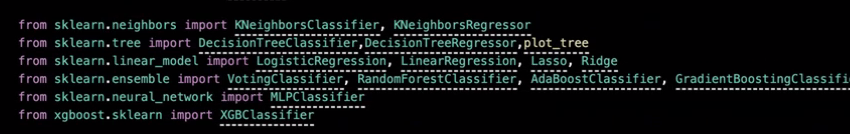

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msn

from collections import Counter
from matplotlib.colors import ListedColormap

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder, KBinsDiscretizer, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost.sklearn import XGBClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, mean_squared_error, RocCurveDisplay, mean_absolute_percentage_error
from sklearn.metrics._scorer import _SCORERS

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')

In [2]:
wine = pd.read_csv('Dataset/white_wine.csv')
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0


In [3]:
wine['alcohol'].fillna(wine['alcohol'].median(),inplace=True)

In [4]:
wine['label'] = np.where(wine['quality']>6,1,0)
X = wine[['alcohol','density']]
y = wine['label']
display(X,y)

,alcohol,density
0,8.8,1.0010
1,9.5,0.9940
2,10.1,0.9951
3,9.9,0.9956
4,9.9,0.9956
...,...,...
515,10.4,0.9926
516,9.1,0.9934
517,10.4,0.9920
518,10.8,0.9918


0      0
1      0
2      0
3      0
4      0
      ..
515    0
516    0
517    0
518    0
519    0
Name: label, Length: 520, dtype: int32

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2020,
    stratify=y
)

In [6]:
# Modeling Base
lr = LogisticRegression(random_state = 2020)
dt = DecisionTreeClassifier(max_depth=5,random_state=2020)
knn = KNeighborsClassifier(n_neighbors=3)

In [7]:
for clfs, clf_name in zip([lr,dt,knn],['Logistic Regression', 'Decision Tree', 'KNN']):
    clfs.fit(X_train,y_train)
    y_pred = clfs.predict(X_test)
    print(clf_name + ':')
    print(classification_report(y_test,y_pred))




Logistic Regression:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92        84
           1       0.75      0.45      0.56        20

    accuracy                           0.87       104
   macro avg       0.82      0.71      0.74       104
weighted avg       0.86      0.87      0.85       104

Decision Tree:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        84
           1       1.00      0.90      0.95        20

    accuracy                           0.98       104
   macro avg       0.99      0.95      0.97       104
weighted avg       0.98      0.98      0.98       104

KNN:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        84
           1       0.75      0.75      0.75        20

    accuracy                           0.90       104
   macro avg       0.85      0.85      0.85       104
weighted avg       0.90      0.90

In [8]:
# Voting classifier
lr = LogisticRegression(solver='liblinear',C=0.01,random_state = 2020)
dt = DecisionTreeClassifier(max_depth=5,random_state=2020)
knn = KNeighborsClassifier(n_neighbors=3)

vc = VotingClassifier([('clf1',lr),('clf2',dt),('clf3',knn)],voting='soft')

In [9]:
vc.fit(X_train,y_train)

VotingClassifier(estimators=[('clf1',
                              LogisticRegression(C=0.01, random_state=2020,
                                                 solver='liblinear')),
                             ('clf2',
                              DecisionTreeClassifier(max_depth=5,
                                                     random_state=2020)),
                             ('clf3', KNeighborsClassifier(n_neighbors=3))],
                 voting='soft')

In [10]:
y_pred = vc.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98        84
           1       1.00      0.85      0.92        20

    accuracy                           0.97       104
   macro avg       0.98      0.93      0.95       104
weighted avg       0.97      0.97      0.97       104



In [13]:
# Model improvements
lr = LogisticRegression(solver='liblinear',C=0.01,random_state = 2020)
lr_poly = PolynomialFeatures(degree=3, interaction_only=False, include_bias=False)
pipe_lr = Pipeline([('preprocess',lr_poly),('clf',lr)])
dt = DecisionTreeClassifier(max_depth=5,random_state=2020)
knn = KNeighborsClassifier(n_neighbors=3)
pipe_knn = Pipeline([('preprocess',StandardScaler()),('clf',knn)])
display(pipe_lr,pipe_knn)

Pipeline(steps=[('preprocess',
                 PolynomialFeatures(degree=3, include_bias=False)),
                ('clf',
                 LogisticRegression(C=0.01, random_state=2020,
                                    solver='liblinear'))])

Pipeline(steps=[('preprocess', StandardScaler()),
                ('clf', KNeighborsClassifier(n_neighbors=3))])

In [14]:
for clfs, clf_name in zip([pipe_lr,dt,pipe_knn],['Logistic Regression', 'Decision Tree', 'KNN']):
    clfs.fit(X_train,y_train)
    y_pred = clfs.predict(X_test)
    print(clf_name + ':')
    print(classification_report(y_test,y_pred))

Logistic Regression:
              precision    recall  f1-score   support

           0       0.88      0.96      0.92        84
           1       0.75      0.45      0.56        20

    accuracy                           0.87       104
   macro avg       0.82      0.71      0.74       104
weighted avg       0.86      0.87      0.85       104

Decision Tree:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        84
           1       1.00      0.90      0.95        20

    accuracy                           0.98       104
   macro avg       0.99      0.95      0.97       104
weighted avg       0.98      0.98      0.98       104

KNN:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99        84
           1       0.95      0.95      0.95        20

    accuracy                           0.98       104
   macro avg       0.97      0.97      0.97       104
weighted avg       0.98      0.98

In [15]:
lr = LogisticRegression(solver='liblinear',C=0.01,random_state = 2020)
lr_poly = PolynomialFeatures(degree=3, interaction_only=False, include_bias=False)
pipe_lr = Pipeline([('preprocess',lr_poly),('clf',lr)])
dt = DecisionTreeClassifier(max_depth=5,random_state=2020)
knn = KNeighborsClassifier(n_neighbors=3)
pipe_knn = Pipeline([('preprocess',StandardScaler()),('clf',knn)])

vc = VotingClassifier([('clf1',pipe_lr),('clf2',dt),('clf3',pipe_knn)],voting='soft')

In [16]:
vc.fit(X_train,y_train)

VotingClassifier(estimators=[('clf1',
                              Pipeline(steps=[('preprocess',
                                               PolynomialFeatures(degree=3,
                                                                  include_bias=False)),
                                              ('clf',
                                               LogisticRegression(C=0.01,
                                                                  random_state=2020,
                                                                  solver='liblinear'))])),
                             ('clf2',
                              DecisionTreeClassifier(max_depth=5,
                                                     random_state=2020)),
                             ('clf3',
                              Pipeline(steps=[('preprocess', StandardScaler()),
                                              ('clf',
                                               KNeighborsClassifier(n_neighbors=3))]))],
                 voting='soft')

In [17]:
y_pred = vc.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99        84
           1       1.00      0.90      0.95        20

    accuracy                           0.98       104
   macro avg       0.99      0.95      0.97       104
weighted avg       0.98      0.98      0.98       104



The model improved from 0.92 to 0.95 f1_score

## Intro for Random Forest

In [86]:
bankloan = pd.read_csv('Dataset/bankloan.csv')
bankloan

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1
1,27,1,10,6,31,17.3,1.362202,4.000798,0
2,40,1,15,14,55,5.5,0.856075,2.168925,0
3,41,1,15,14,120,2.9,2.658720,0.821280,0
4,24,2,2,0,28,17.3,1.787436,3.056564,1
...,...,...,...,...,...,...,...,...,...
695,36,2,6,15,27,4.6,0.262062,0.979938,1
696,29,2,6,4,21,11.5,0.369495,2.045505,0
697,33,1,15,3,32,7.6,0.491264,1.940736,0
698,45,1,19,22,77,8.4,2.302608,4.165392,0


In [87]:
features = ['age', 'employ', 'debtinc', 'creddebt', 'othdebt']
target = ['default']

X = bankloan[features]
y = bankloan[target]

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify= y,
    random_state= 2020
)

In [88]:
# checking
# Counter(y) --> for series
y.value_counts(normalize=True) # --> for DataFrame

default
0          0.738571
1          0.261429
Name: proportion, dtype: float64

In [89]:
# random forest modeling
rf = RandomForestClassifier(n_estimators=100, max_depth=3, max_features=3, random_state=2020)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.94      0.87       103
           1       0.68      0.35      0.46        37

    accuracy                           0.79       140
   macro avg       0.74      0.65      0.67       140
weighted avg       0.77      0.79      0.76       140



## Game for to gain highest f1score

In [90]:
# random forest modeling
# rf = RandomForestClassifier(n_estimators=100, max_depth=3, max_features=3, random_state=2020)
# rf.fit(X_train,y_train)
# y_pred = rf.predict(X_test)
# print(classification_report(y_test,y_pred))

In [97]:
bankloan = pd.read_csv('Dataset/bankloan.csv')
bankloan

,age,ed,employ,address,income,debtinc,creddebt,othdebt,default
0,41,3,17,12,176,9.3,11.359392,5.008608,1
1,27,1,10,6,31,17.3,1.362202,4.000798,0
2,40,1,15,14,55,5.5,0.856075,2.168925,0
3,41,1,15,14,120,2.9,2.658720,0.821280,0
4,24,2,2,0,28,17.3,1.787436,3.056564,1
...,...,...,...,...,...,...,...,...,...
695,36,2,6,15,27,4.6,0.262062,0.979938,1
696,29,2,6,4,21,11.5,0.369495,2.045505,0
697,33,1,15,3,32,7.6,0.491264,1.940736,0
698,45,1,19,22,77,8.4,2.302608,4.165392,0


In [132]:
# Define features and target
features = ['age', 'employ', 'debtinc', 'creddebt', 'othdebt']
target = ['default']

# Split the dataset
X = bankloan[features]
y = bankloan[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2020
)

# Define multiple Random Forest models with different hyperparameters
rf1 = RandomForestClassifier(n_estimators=100, max_depth=5, max_features=3, min_samples_leaf=2,min_samples_split=2, class_weight='balanced', random_state=2020)
rf2 = RandomForestClassifier(n_estimators=250, max_depth=10, max_features=2, min_samples_leaf=3,min_samples_split=4, class_weight='balanced',random_state=2020)
rf3 = RandomForestClassifier(n_estimators=500, max_depth=25, max_features=4, min_samples_leaf=4,min_samples_split=6, class_weight='balanced',random_state=2020)

# Create a Voting Classifier
voting_clf = VotingClassifier(
    estimators=[
        ('rf1', rf1),
        ('rf2', rf2),
        ('rf3', rf3)
    ],
    voting='hard'
)

voting_clf.fit(X_train, y_train)

y_pred = voting_clf.predict(X_test)

print("Classification Report for Voting Classifier:")
print(classification_report(y_test, y_pred))



Classification Report for Voting Classifier:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       103
           1       0.59      0.65      0.62        37

    accuracy                           0.79       140
   macro avg       0.73      0.74      0.73       140
weighted avg       0.79      0.79      0.79       140

